<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [19]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

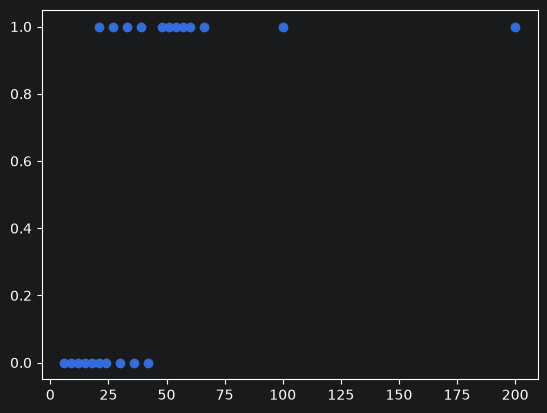

In [3]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [4]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


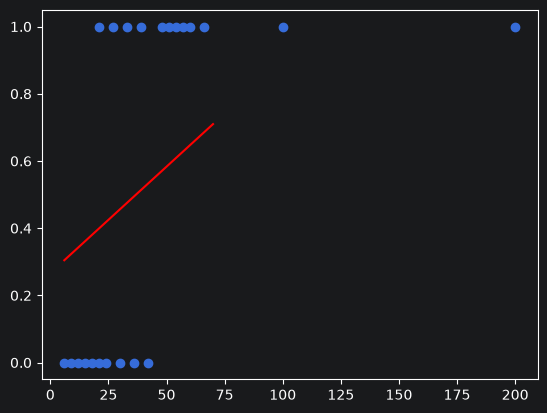

In [5]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [15]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)
        
    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))
    
    def predict(self, x):
        return self.sigmoid(x)
    
    def coefs(self):
        return self.a
      
    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
    
    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean() 

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [20]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [8]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 29.02569270133972 сек.'

'Время обучения: 27.56481671333313 сек.'

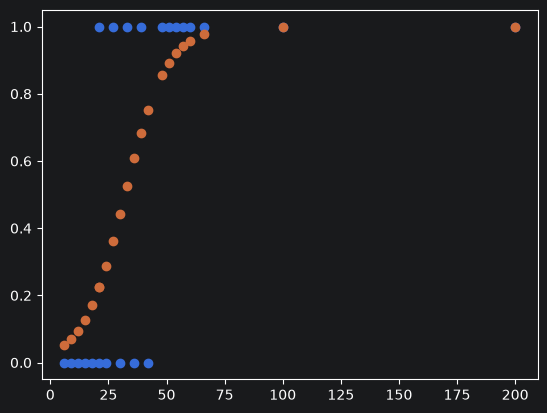

In [9]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [10]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.599005
1,0.112157


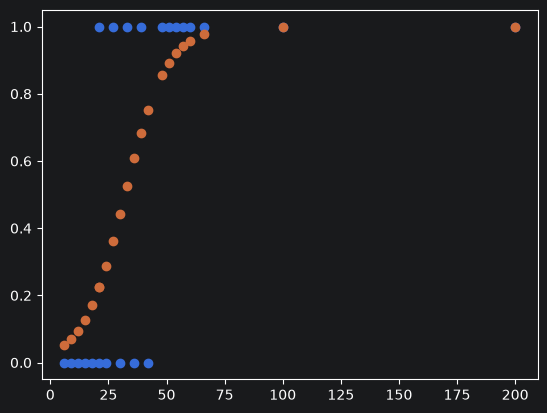

In [11]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [12]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.599005
1,0.112157


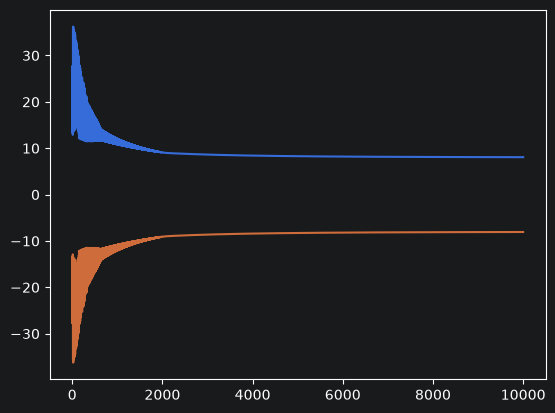

In [13]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [14]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

In [2]:
train_df = pd.read_csv("insclass_train.csv")

In [3]:
train_df.head()

,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,...,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0,NaN,0.0,NaN,0,...,C,j2,h45,0,0.0,0,1,19.323463,t1,0
1,w160,0,0,7,q11,106.0,NaN,0.0,NaN,0,...,C,j33,h234,0,1.0,0,1,41.177900,t1,0
2,w200,0,0,4,q3,123.0,NaN,0.0,NaN,0,...,B,j12,h28,0,0.0,0,1,3.614395,t1,0
3,w200,0,0,9,q3,102.0,NaN,0.0,NaN,0,...,C,j12,h64,0,1.0,0,0,49.041674,t1,0
4,w200,0,0,18,q20,117.0,NaN,0.0,NaN,0,...,C,j111,h991,0,1.0,0,0,17.909612,t1,0


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 151406 entries, 0 to 151405
Data columns (total 29 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   variable_1   151406 non-null  str    
 1   variable_2   151406 non-null  int64  
 2   variable_3   151406 non-null  int64  
 3   variable_4   151406 non-null  int64  
 4   variable_5   151406 non-null  str    
 5   variable_6   151295 non-null  float64
 6   variable_7   55767 non-null   float64
 7   variable_8   121507 non-null  float64
 8   variable_9   16970 non-null   float64
 9   variable_10  151406 non-null  int64  
 10  variable_11  151406 non-null  int64  
 11  variable_12  149878 non-null  float64
 12  variable_13  149749 non-null  float64
 13  variable_14  148479 non-null  float64
 14  variable_15  13 non-null      float64
 15  variable_16  151394 non-null  float64
 16  variable_17  151394 non-null  float64
 17  variable_18  151394 non-null  float64
 18  variable_19  151406 non-null  float

In [5]:
train_df.describe()

,variable_2,variable_3,variable_4,variable_6,variable_7,variable_8,variable_9,variable_10,variable_11,variable_12,...,variable_16,variable_17,variable_18,variable_19,variable_23,variable_24,variable_25,variable_26,variable_27,target
count,151406.000000,151406.0,151406.000000,151295.000000,55767.000000,121507.000000,1.697000e+04,151406.000000,151406.000000,149878.000000,...,151394.000000,151394.000000,151394.000000,151406.000000,151406.000000,149199.000000,151406.000000,151406.000000,149339.000000,151406.000000
mean,0.017047,0.0,11.307676,117.937741,1865.909732,0.000337,3.459045e+32,0.017364,0.019537,133.099956,...,132.273151,85.507594,109.164414,139.913519,0.201769,0.737096,0.097612,0.862562,15.551271,0.095498
std,0.129446,0.0,6.925851,50.334055,848.398846,0.018366,4.506062e+34,0.130624,0.138403,87.881579,...,42.465123,29.151078,67.577224,18.585624,0.401322,0.440212,0.296790,0.344311,12.004247,0.293903
min,0.000000,0.0,2.000000,1.000000,1.000000,0.000000,-2.191600e+04,0.000000,0.000000,0.000000,...,28.130592,80.985224,19.287400,102.172584,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.0,6.000000,86.000000,1499.000000,0.000000,7.808400e+04,0.000000,0.000000,66.827923,...,98.648082,80.985224,65.116010,127.113159,0.000000,0.000000,0.000000,1.000000,6.447149,0.000000
50%,0.000000,0.0,10.000000,107.000000,1598.000000,0.000000,1.000000e+05,0.000000,0.000000,121.261910,...,118.116608,80.985224,80.985224,131.419341,0.000000,1.000000,0.000000,1.000000,12.200897,0.000000
75%,0.000000,0.0,14.000000,137.000000,1998.000000,0.000000,1.000000e+05,0.000000,0.000000,175.818287,...,162.514016,80.985224,139.401847,148.905712,0.000000,1.000000,0.000000,1.000000,20.731525,0.000000
max,1.000000,0.0,80.000000,1975.000000,35697.000000,1.000000,5.870000e+36,1.000000,1.000000,842.774591,...,214.256572,273.413449,376.183487,284.372991,1.000000,1.000000,1.000000,1.000000,100.563999,1.000000


### EDA

In [6]:
cat_cols = ['variable_1', 'variable_5', 'variable_20', 'variable_21', 'variable_22', 'variable_28']
bin_cols = ['variable_2', 'variable_8', 'variable_10', 'variable_11', 'variable_23', 'variable_24', 'variable_25', 'variable_26']
num_cols = ['variable_4', 'variable_6', 'variable_7', 'variable_9', 'variable_12', 'variable_13', 'variable_14', 'variable_15',
            'variable_16', 'variable_17', 'variable_18', 'variable_19', 'variable_27']

print(train_df['target'].value_counts(normalize=True))
na = train_df.isna().sum()
na = na[na > 0]
print(na)
print(na / len(train_df))
print(train_df['variable_3'].unique())

target
0    0.904502
1    0.095498
Name: proportion, dtype: float64
variable_6        111
variable_7      95639
variable_8      29899
variable_9     134436
variable_12      1528
variable_13      1657
variable_14      2927
variable_15    151393
variable_16        12
variable_17        12
variable_18        12
variable_20         1
variable_24      2207
variable_27      2067
dtype: int64
variable_6     0.000733
variable_7     0.631672
variable_8     0.197476
variable_9     0.887917
variable_12    0.010092
variable_13    0.010944
variable_14    0.019332
variable_15    0.999914
variable_16    0.000079
variable_17    0.000079
variable_18    0.000079
variable_20    0.000007
variable_24    0.014577
variable_27    0.013652
dtype: float64
[0]


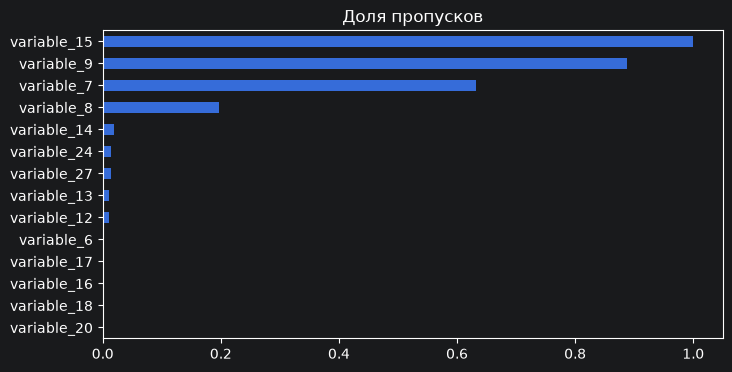

In [7]:
plt.figure(figsize=(8, 4))
(na / len(train_df)).sort_values().plot(kind='barh')
plt.title('Доля пропусков')
plt.show()

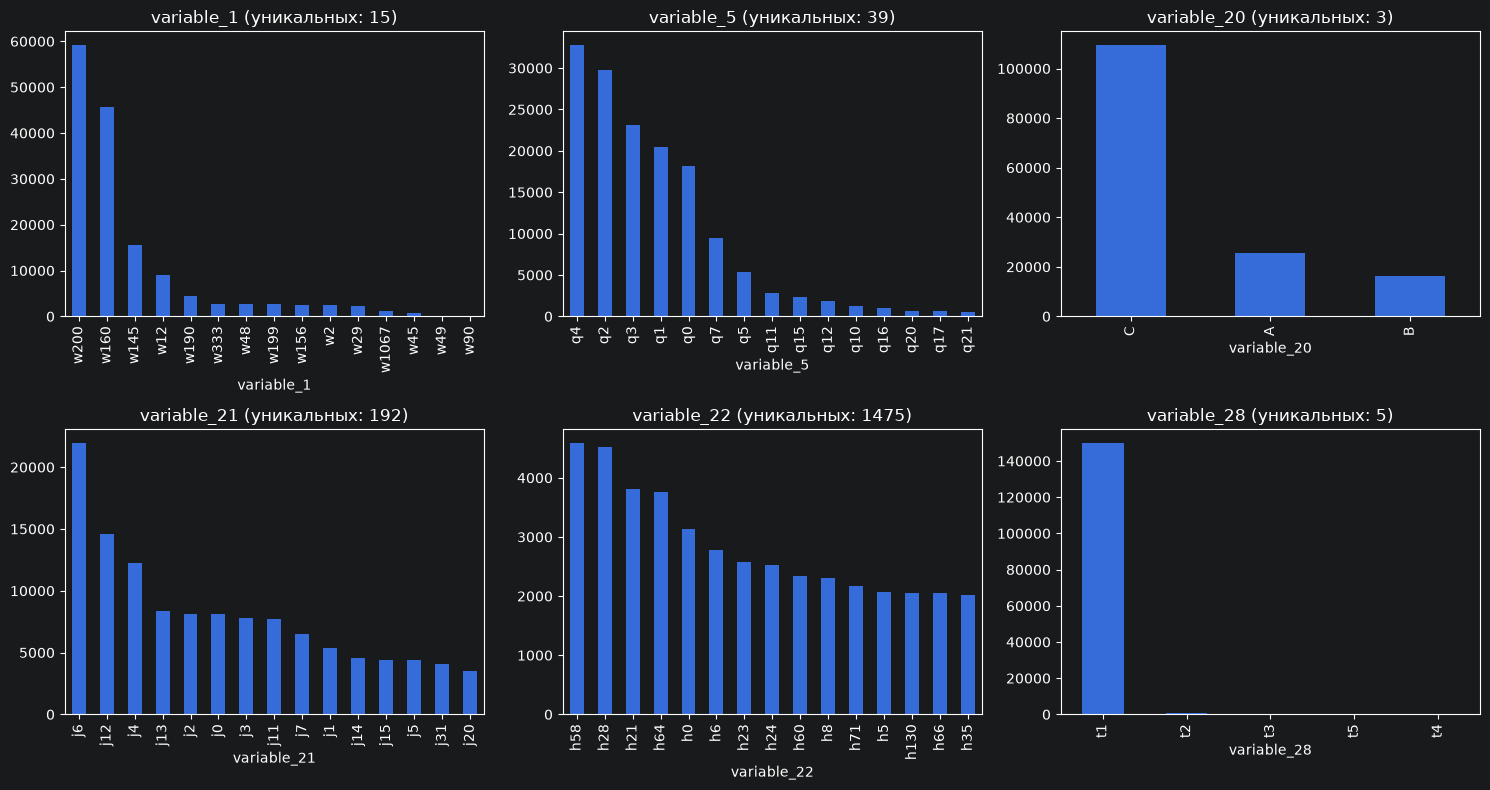

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    train_df[c].value_counts().head(15).plot(kind='bar', ax=ax)
    ax.set_title(c + ' (уникальных: ' + str(train_df[c].nunique()) + ')')
plt.tight_layout()
plt.show()

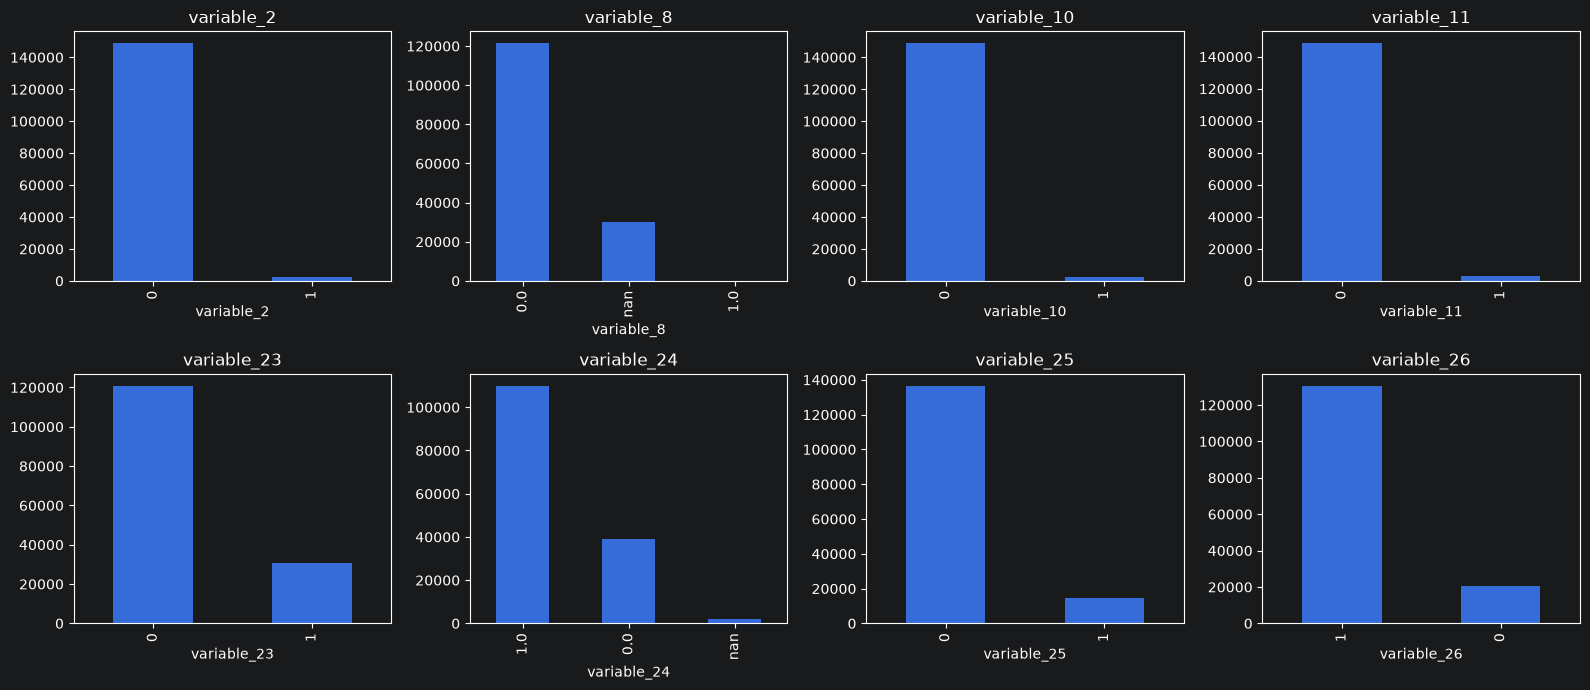

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), bin_cols):
    train_df[c].value_counts(dropna=False).plot(kind='bar', ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

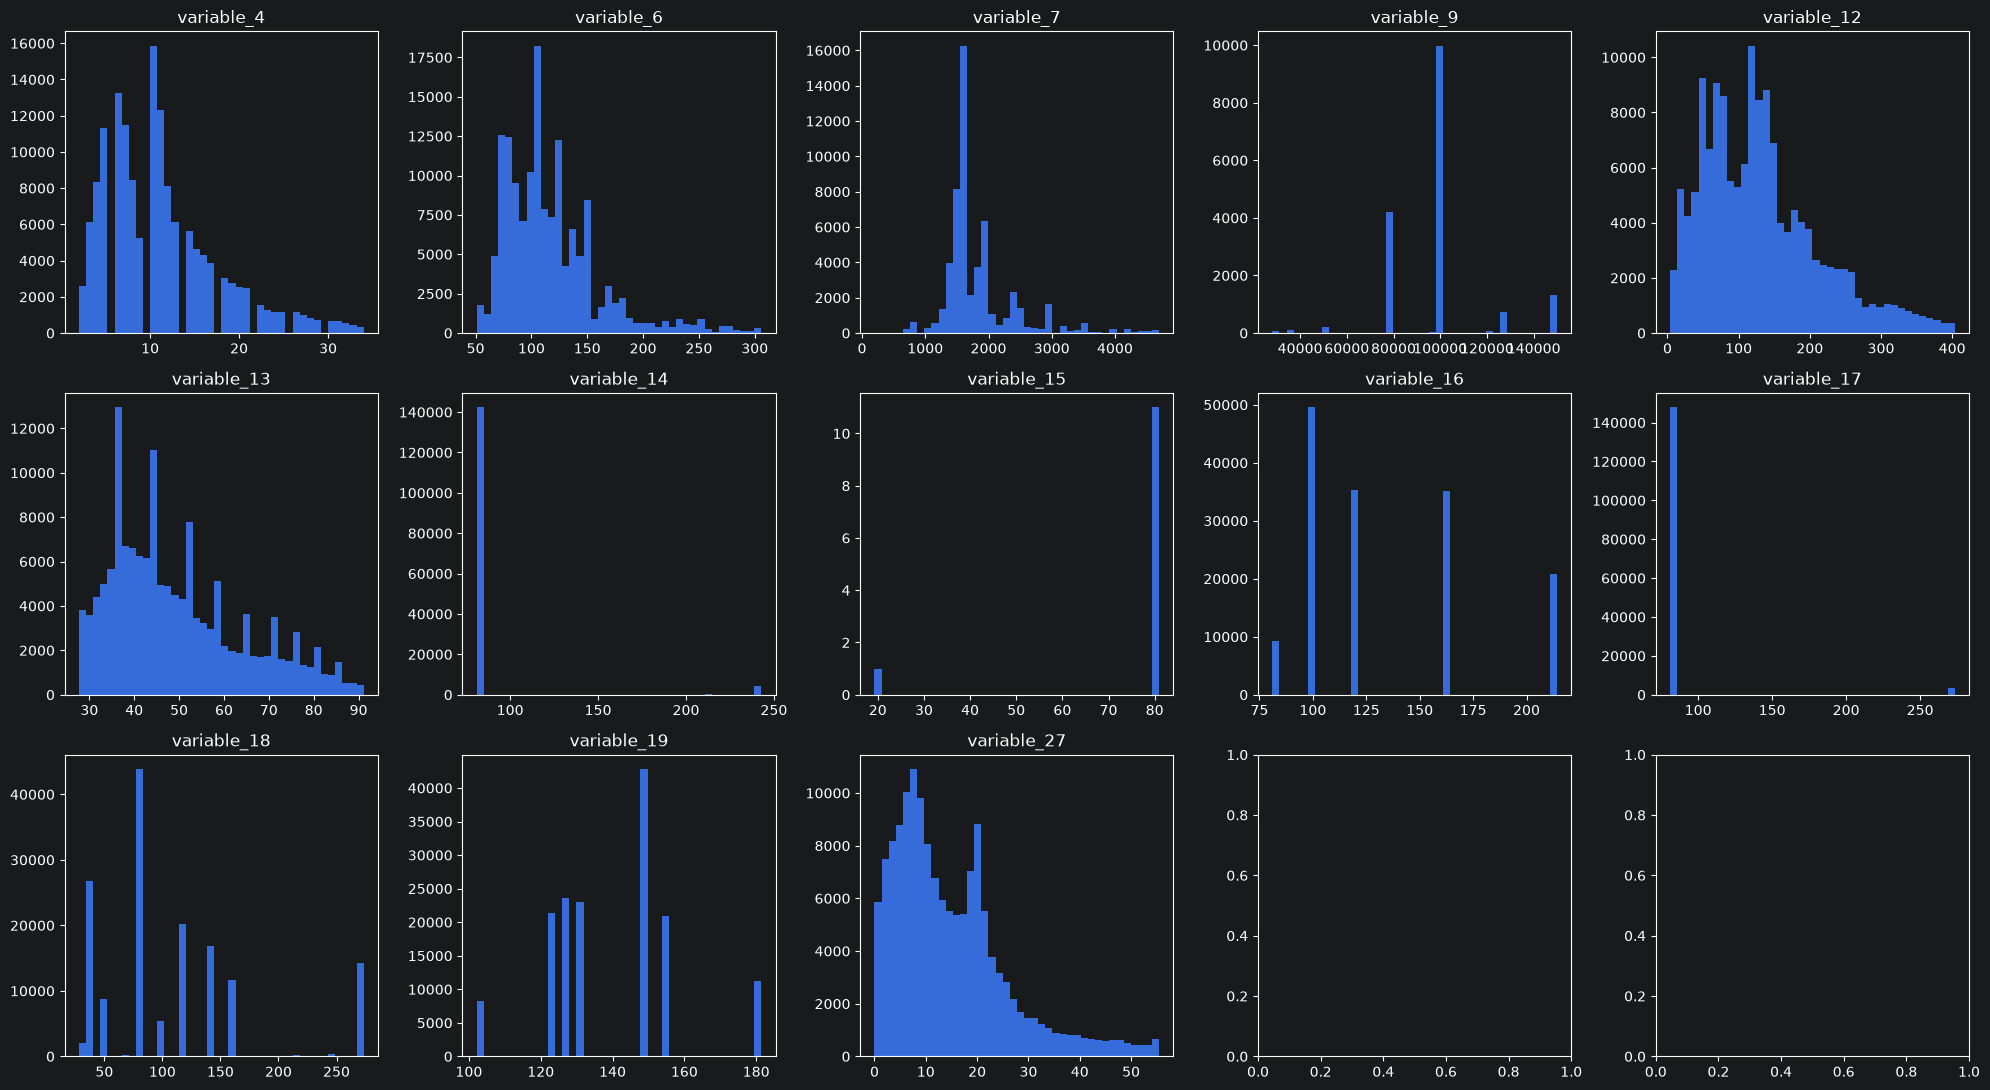

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_cols):
    s = train_df[c].dropna()
    ax.hist(s[(s >= s.quantile(0.01)) & (s <= s.quantile(0.99))], bins=40)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [11]:
print(train_df[num_cols].quantile([0, 0.001, 0.01, 0.5, 0.99, 0.999, 1]).T)
print('variable_9 < 0:', (train_df['variable_9'] < 0).sum())
print('variable_9 > 300000:', (train_df['variable_9'] > 300000).sum())
print('variable_6 < 20:', (train_df['variable_6'] < 20).sum())
print('variable_7 < 100:', (train_df['variable_7'] < 100).sum())
print('variable_4 > 45:', (train_df['variable_4'] > 45).sum())
print('стаж больше возраста:', (train_df['variable_27'] > train_df['variable_13']).sum())

                    0.000         0.001         0.010          0.500  \
variable_4       2.000000      2.000000      2.000000      10.000000   
variable_6       1.000000     32.000000     51.000000     107.000000   
variable_7       1.000000      1.000000    192.240000    1598.000000   
variable_9  -21916.000000 -11916.000000  28084.000000  100000.000000   
variable_12      0.000000      0.000000      3.614395     121.261910   
variable_13     20.731525     24.920571     27.684222      46.438089   
variable_14     80.985224     80.985224     80.985224      80.985224   
variable_15      2.894262      3.090980      4.861439      80.985224   
variable_16     28.130592     28.130592     80.985224     118.116608   
variable_17     80.985224     80.985224     80.985224      80.985224   
variable_18     19.287400     28.130592     28.130592      80.985224   
variable_19    102.172584    102.172584    102.172584     131.419341   
variable_27      0.000000      0.000000      0.000000      12.20

Выводы EDA: классы несбалансированы (около 9.5% единиц); variable_3 константа (удаляем); сильные пропуски в variable_7, variable_8, variable_9, variable_15; в variable_9 есть отрицательный пробег и значения порядка 1e36, в variable_7 и variable_6 нереальные значения (1 см3, 1 л.с.), в variable_4 редкие значения-выбросы. У variable_21 и variable_22 очень много категорий, поэтому для one-hot оставляем только частые.

### Препроцессинг

In [12]:
rules = {'variable_6': (20, np.inf), 'variable_7': (100, np.inf), 'variable_9': (0, 300000)}
top_k = 20

def preprocess(df, params=None):
    fit = params is None
    if fit:
        params = {'top': {}, 'miss': {}, 'mean': {}, 'std': {}, 'bounds': {}}
    cols, names = [], []

    for c in cat_cols:
        s = df[c]
        if fit:
            params['top'][c] = list(s.value_counts().head(top_k).index)
            params['miss'][c] = bool(s.isna().any())
        for k in params['top'][c]:
            cols.append((s == k).astype(float).values)
            names.append(c + '=' + str(k))
        cols.append((s.notna() & ~s.isin(params['top'][c])).astype(float).values)
        names.append(c + '=other')
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(c + '_missing')

    for c in bin_cols:
        s = df[c].astype(float)
        if fit:
            params['miss'][c] = bool(s.isna().any())
            params['mean'][c] = s.mean()
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(c + '_missing')
        cols.append(s.fillna(params['mean'][c]).values)
        names.append(c)

    for c in num_cols:
        lo, hi = rules.get(c, (0, np.inf))
        s = df[c].astype(float)
        s = s.where((s >= lo) & (s <= hi))
        if fit:
            q = s.quantile([0.001, 0.999])
            params['bounds'][c] = (q.iloc[0], q.iloc[1])
        s = s.where((s >= params['bounds'][c][0]) & (s <= params['bounds'][c][1]))
        if fit:
            params['miss'][c] = bool(s.isna().any())
            params['mean'][c] = s.mean()
            params['std'][c] = s.std()
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(c + '_missing')
        s = s.fillna(params['mean'][c])
        cols.append(((s - params['mean'][c]) / params['std'][c]).values)
        names.append(c)

    cols.insert(0, np.ones(len(df)))
    names.insert(0, 'intercept')
    return np.column_stack(cols), names, params

### Разделение на train и test

In [13]:
rng = np.random.RandomState(42)
idx = rng.permutation(len(train_df))
n_test = int(0.2 * len(train_df))
test_part = train_df.iloc[idx[:n_test]]
train_part = train_df.iloc[idx[n_test:]]

X_train, names, params = preprocess(train_part)
X_test, _, _ = preprocess(test_part, params)
y_train = train_part['target'].values.reshape(-1, 1)
y_test = test_part['target'].values.reshape(-1, 1)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())
print(np.isnan(X_train).sum(), np.isnan(X_test).sum())

(121125, 1289) (30281, 1289)
0.09515789473684211 0.0968594167960107
0 0


### Модель и метрики

In [24]:
class LogisticRegressionGDExt(LogisticRegressionGD):
    def sigmoid(self, x):
        z = np.clip(x @ self.a, -30, 30)
        return 1 / (1 + np.exp(-z))

    def LogLikelihood(self, x, Y):
        p = np.clip(self.predict(x), 1e-12, 1 - 1e-12)
        return (Y * np.log(p) + (1 - Y) * np.log(1 - p)).mean()

    def CrossEntropy(self, x, Y):
        p = np.clip(self.predict(x), 1e-12, 1 - 1e-12)
        return (-Y * np.log(p) - (1 - Y) * np.log(1 - p)).mean()

    def predict_class(self, x, threshold=0.5):
        return (self.predict(x) > threshold).astype(int)

def confusion(y_true, y_pred):
    y_true = y_true.ravel()
    y_pred = y_pred.ravel()
    tp = ((y_true == 1) & (y_pred == 1)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    tn = ((y_true == 0) & (y_pred == 0)).sum()
    return tp, fp, fn, tn

def precision(y_true, y_pred):
    tp, fp, fn, tn = confusion(y_true, y_pred)
    return tp / (tp + fp) if tp + fp > 0 else 0.0

def recall(y_true, y_pred):
    tp, fp, fn, tn = confusion(y_true, y_pred)
    return tp / (tp + fn) if tp + fn > 0 else 0.0

def f1(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * p * r / (p + r) if p + r > 0 else 0.0

def roc_auc(y_true, scores):
    y_true = y_true.ravel()
    scores = scores.ravel()
    order = np.argsort(scores)
    ranks = np.empty(len(scores))
    ranks[order] = np.arange(1, len(scores) + 1)
    _, inv, counts = np.unique(scores, return_inverse=True, return_counts=True)
    ranks = (np.bincount(inv, weights=ranks) / counts)[inv]
    n_pos = (y_true == 1).sum()
    n_neg = (y_true == 0).sum()
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def best_threshold_f1(y_true, scores):
    best_t, best_f = 0.5, -1
    for t in np.linspace(0.02, 0.9, 45):
        f = f1(y_true, (scores > t).astype(int))
        if f > best_f:
            best_t, best_f = t, f
    return best_t

def best_threshold_recall(y_true, scores):
    best_t, best_f = 0.5, -1
    for t in np.linspace(0.02, 0.9, 45):
        f = recall(y_true, (scores > t).astype(int))
        if f > best_f:
            best_t, best_f = t, f
    return best_t

def evaluate(model, X, y, threshold=0.5):
    scores = model.predict(X)
    pred = (scores > threshold).astype(int)
    return {'threshold': round(float(threshold), 3), 'precision': precision(y, pred), 'recall': recall(y, pred),
            'f1': f1(y, pred), 'roc_auc': roc_auc(y, scores)}

Время CE: 204.04670667648315 LL: 54.03402328491211


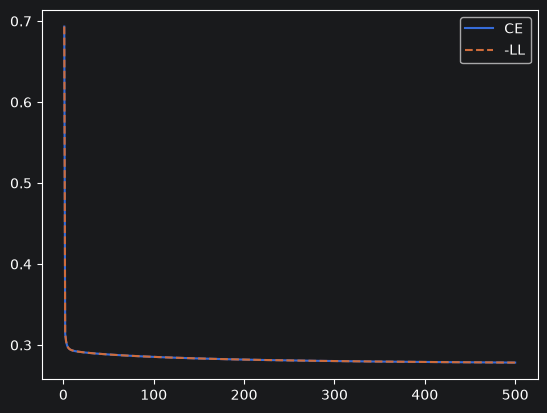

In [21]:
alpha = 1
max_steps = 500

start = time.time()
model_CE = LogisticRegressionGDExt()
steps_CE, errors_CE = model_CE.fit(X_train, y_train, alpha=alpha, max_steps=max_steps, Rtype='CE')
time_CE = time.time() - start

start = time.time()
model_LL = LogisticRegressionGDExt()
steps_LL, errors_LL = model_LL.fit(X_train, y_train, alpha=alpha, max_steps=max_steps, Rtype='LL')
time_LL = time.time() - start

print('Время CE:', time_CE, 'LL:', time_LL)
plt.plot(steps_CE, errors_CE, label='CE')
plt.plot(steps_LL, [-e for e in errors_LL], '--', label='-LL')
plt.legend()
plt.show()

In [25]:
res = {}
for name, model in [('CE (градиентный спуск)', model_CE), ('LL (градиентный подъем)', model_LL)]:
    res[name + ', порог 0.5'] = evaluate(model, X_test, y_test, 0.5)
    t1 = best_threshold_f1(y_train, model.predict(X_train))
    t2 = best_threshold_recall(y_train, model.predict(X_train))
    res[name + ', порог по f1'] = evaluate(model, X_test, y_test, t1)
    res[name + ', порог по recall'] = evaluate(model, X_test, y_test, t2)
pd.DataFrame(res).T

,threshold,precision,recall,f1,roc_auc
"CE (градиентный спуск), порог 0.5",0.50,0.992647,0.138084,0.242442,0.668449
"CE (градиентный спуск), порог по f1",0.14,0.297932,0.255370,0.275014,0.668449
"CE (градиентный спуск), порог по recall",0.02,0.096930,1.000000,0.176729,0.668449
"LL (градиентный подъем), порог 0.5",0.50,0.992647,0.138084,0.242442,0.668449
"LL (градиентный подъем), порог по f1",0.14,0.297932,0.255370,0.275014,0.668449
"LL (градиентный подъем), порог по recall",0.02,0.096930,1.000000,0.176729,0.668449


In [26]:
coef = pd.Series(model_CE.coefs().ravel(), index=names)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)

variable_27_missing    1.736694
variable_13_missing    1.065203
variable_24_missing    0.831162
variable_15_missing   -0.623630
intercept             -0.620323
variable_28=t1        -0.383328
variable_20=C         -0.326981
variable_20=B         -0.297650
variable_26           -0.285912
variable_14_missing    0.268142
variable_11            0.243807
variable_2            -0.242435
variable_13           -0.220418
variable_8_missing    -0.209864
variable_5=q4         -0.193381
dtype: float64